# 04. Quality-Diversity Benchmark Comparison

This notebook evaluates the 100,000-evaluation generative benchmark across algorithms.

> **Novelty Filter Enforced**: All hits, scaffolds, discovery trajectories, and rarefaction curves strictly exclude molecules with Morgan/ECFP4 Tanimoto similarity $> 0.7$ to known training actives ($\\mathrm{Tc} \\leq 0.7$). Only structurally novel active compounds are evaluated.


In [61]:
from __future__ import annotations

import io
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

ROOT = Path.cwd()
while not (ROOT / "chemistry").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.benchmark_cache import (
    DEFAULT_GREY,
    EVAL_GRID,
    FIGS,
    add_stat_box,
    apply_strict_style,
    load_or_compute_benchmark_cache,
    style_axes,
)

apply_strict_style()
bundle = load_or_compute_benchmark_cache(force_recompute=False)

run_metrics_df = bundle["run_metrics_df"]
method_table = bundle["method_table"]
discovery_curves = bundle["discovery_curves"]
scaffold_eval_curves = bundle["scaffold_eval_curves"]
rarefaction_curves = bundle["rarefaction_curves"]
rolling_p_curves = bundle["rolling_p_curves"]
coverage_curves = bundle["coverage_curves"]
mcs_pairwise_by_method = bundle["mcs_pairwise_by_method"]
mcs_seed_medians = bundle["mcs_seed_medians"]
top_div_by_method = bundle["top_div_by_method"]
top_raw_by_method = bundle["top_raw_by_method"]


METHODS_TO_PLOT = [
    "cma_me_imp_mu_thresh", 
    "cma_me_opt",            
    "cma_me_imp_mu",                
    "cma_mae_thresh",       
    "naive",                
]


COLORS = {
    "cma_me_imp_mu_thresh": "#ff9933", 
    "cma_me_opt":           "#6666FF",  
    "cma_me_imp_mu":        "#e15759", 
    "cma_mae_thresh":       "#76B7B2",  
    "naive":                "#EDC949",  
    "me_map_elites_thresh": "#292966",  
    "cma_me_imp_thresh":    "#9999FF",  
    "cma_mae":              "#666666",
}

NAMES = {
    "cma_me_imp_mu_thresh": "CMA-ME imp-$\\mu$ with a threshold",
    "naive":                "Naive prior $\\mathcal{N}(0, I)$",
    "cma_es":               "CMA-ES (1-cell obj)",
    "cma_me_opt":           "CMA without diversity",
    "cma_me_opt_thresh":    "CMA-ME opt with a threshold",
    "cma_mae":              "CMA-MAE (unthresholded)",
    "cma_mae_thresh":       "CMA-MAE with a threshold",
    "me_map_elites":        "ME-MAP-Elites",
    "me_map_elites_thresh": "ME-MAP-Elites with a threshold",
    "cma_me_imp":           "CMA-ME imp-filter",
    "cma_me_imp_thresh":    "CMA-ME imp-filter with a threshold",
    "cma_me_imp_mu":        "CMA-ME imp-$\\mu$",
    "cma_me_basic":         "CMA-ME basic",
    "cma_me_basic_thresh":  "CMA-ME basic with a threshold",
    "cma_me_mixed":         "CMA-ME mixed",
    "cma_me_mixed_thresh":  "CMA-ME mixed with a threshold",
    "cma_me_rd":            "CMA-ME rank-diff",
    "cma_me_rd_thresh":     "CMA-ME rank-diff with a threshold",
    "cma_me_rd_mu":         "CMA-ME rank-diff-$\\mu$",
    "cma_me_rd_mu_thresh":  "CMA-ME rank-diff-$\\mu$ with a threshold",
    "cma_me_obj_bandit":    "CMA-ME obj bandit",
    "map_elites":           "MAP-Elites",
}

def get_col(m): return COLORS.get(m, DEFAULT_GREY)
def get_lbl(m): return NAMES.get(m, m)
def get_z(m): return 10 if m == "cma_me_imp_mu_thresh" else (8 if m == "naive" else 6)

all_available = list(method_table.index)
selected_methods = [m for m in METHODS_TO_PLOT if m in all_available]
plot_order = list(reversed(selected_methods))

print(f"Loaded benchmark cache. Selected {len(selected_methods)} methods for comparison.")


Loaded cached benchmark bundle from notebooks/cache/06_benchmark_analysis/benchmark_bundle_v1.pkl (122 runs, 29 methods).
Loaded benchmark cache. Selected 5 methods for comparison.


## 1 Summary Metrics Across All 29 Benchmark Algorithms (87 Runs)


In [62]:
display(
    method_table[[
        "hits_mean", "hits_std", "hits_median",
        "generic_scaffolds_mean", "murcko_scaffolds_mean",
        "mcs_tc_median", "coverage_mean", "qd_score_mean", "duplicates_mean",
    ]].round(2)
)


,hits_mean,hits_std,hits_median,generic_scaffolds_mean,murcko_scaffolds_mean,mcs_tc_median,coverage_mean,qd_score_mean,duplicates_mean
cma_es,6022.33,5746.29,3001.0,475.67,1393.67,0.28,1.00,1.00,25711.33
cma_me_opt,5650.40,1203.83,5179.5,488.10,1203.50,0.27,0.81,586.07,32673.10
cma_mae_thresh,5369.10,2835.19,4541.0,520.20,1331.20,0.28,0.83,604.29,30841.00
cma_mae,5260.33,1687.17,4547.0,604.00,1475.00,0.31,0.93,821.06,26068.67
cma_me_obj_bandit_thresh,4870.33,388.08,4830.0,475.67,1140.00,0.27,0.77,553.44,32872.00
cma_me_opt_thresh,4870.33,388.08,4830.0,475.67,1140.00,0.27,0.77,553.44,32872.00
cma_me_obj_bandit,4870.33,388.08,4830.0,475.67,1140.00,0.27,0.77,553.44,32872.00
me_map_elites_thresh,4792.33,2938.82,6464.0,550.00,1435.00,0.33,0.93,730.86,53740.00
cma_me_imp_mu_thresh,4476.00,3612.25,4938.0,481.40,1257.80,0.34,0.93,650.91,11911.40
cma_me_mixed_thresh,4371.00,863.25,4299.0,590.00,1472.33,0.33,0.95,833.56,8887.00


## Figure 1: Cumulative Discovery Curves ($P > 0.6, 0.7, 0.8$)


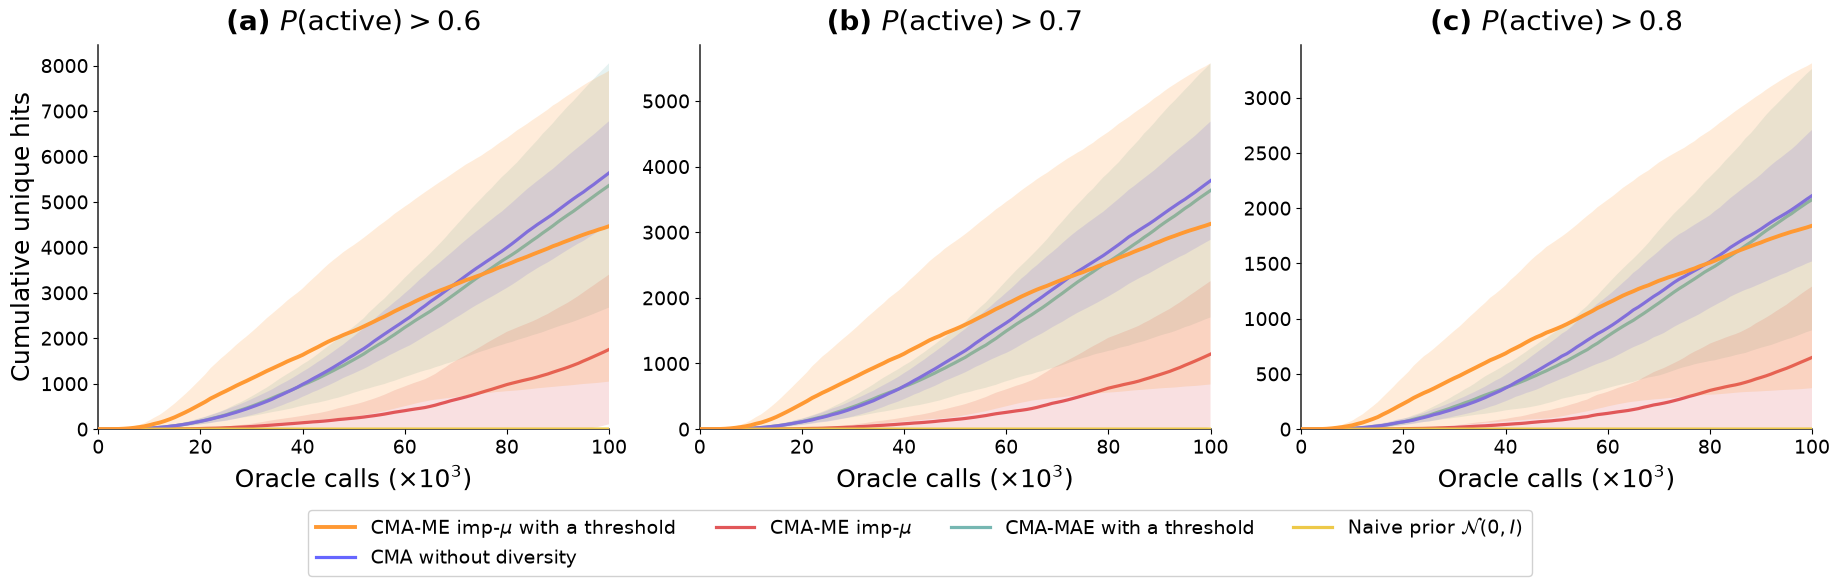

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.8), sharex=True)
panel_specs = [
    (0.6, "(a) $P(\\mathrm{active}) > 0.6$"),
    (0.7, "(b) $P(\\mathrm{active}) > 0.7$"),
    (0.8, "(c) $P(\\mathrm{active}) > 0.8$"),
]

for ax, (thresh, title) in zip(axes, panel_specs):
    style_axes(ax)
    for m in plot_order:
        arrs = [discovery_curves[thresh][(m, s)] for s in (1, 2, 3, 4,5,6,7,8,9,10) if (m, s) in discovery_curves[thresh]]
        if not arrs:
            continue
        mat = np.vstack(arrs)
        mean, std = mat.mean(axis=0), mat.std(axis=0)
        col = get_col(m)
        z = get_z(m)
        lw = 2.8 if m == "cma_me_imp_mu_thresh" else 2.3
        ax.plot(EVAL_GRID / 1e3, mean, color=col, linewidth=lw, label=get_lbl(m), zorder=z)
        ax.fill_between(EVAL_GRID / 1e3, np.maximum(0, mean - std), mean + std, color=col, alpha=0.18, edgecolor="none", zorder=z - 1)
    ax.set_title(title, pad=10)
    ax.set_xlabel("Oracle calls ($\\times 10^3$)")
    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=0)

axes[0].set_ylabel("Cumulative unique hits")

if "cma_me_imp_mu_thresh" in selected_methods and "naive" in selected_methods:
    eva_h = method_table.loc["cma_me_imp_mu_thresh", "hits_06_mean"]
    naive_h = max(method_table.loc["naive", "hits_06_mean"], 1e-6)

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ordered_labels = [get_lbl(m) for m in selected_methods if get_lbl(m) in by_label]
ordered_handles = [by_label[l] for l in ordered_labels]

fig.tight_layout()
fig.subplots_adjust(bottom=0.25)
fig.legend(ordered_handles, ordered_labels, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=min(4, len(ordered_labels)), frameon=True, framealpha=0.9, edgecolor="#CCCCCC", fancybox=True)
plt.show()


## Figure 2: Unique Hits at 100k Oracle Budget


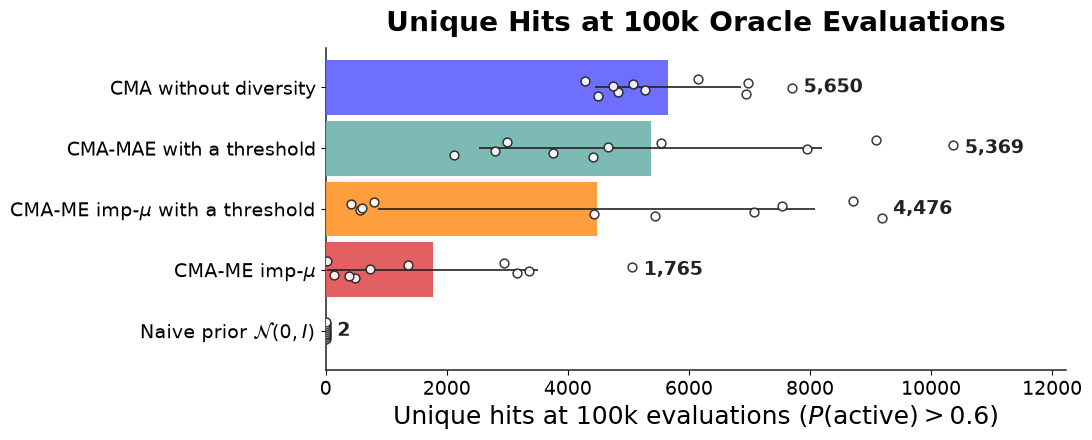

In [64]:
sub_bar = method_table.loc[selected_methods].sort_values("hits_mean", ascending=True)
fig_h = max(4.5, len(sub_bar) * 0.72)
fig, ax = plt.subplots(figsize=(11.0, fig_h))
style_axes(ax)

y_pos = np.arange(len(sub_bar))
means = sub_bar["hits_mean"].to_numpy()
stds = sub_bar["hits_std"].fillna(0.0).to_numpy()
colors = [get_col(m) for m in sub_bar.index]

ax.barh(y_pos, means, height=0.90, color=colors, edgecolor="none", alpha=0.95, zorder=3)
ax.errorbar(means, y_pos, xerr=stds, fmt="none", ecolor="#222222", elinewidth=1.2, capsize=0, zorder=5)

max_x = 0.0
for idx, m in enumerate(sub_bar.index):
    seed_vals = run_metrics_df.loc[run_metrics_df["method"] == m, "hits"].to_numpy()
    max_x = max(max_x, float(seed_vals.max()) if seed_vals.size else 0.0, float(means[idx] + stds[idx]))
    jitter = np.linspace(-0.14, 0.14, len(seed_vals)) if len(seed_vals) > 1 else np.array([0.0])
    ax.scatter(seed_vals, np.full_like(seed_vals, y_pos[idx], dtype=float) + jitter, s=40, facecolor="white", edgecolor="#222222", linewidth=1.1, alpha=0.9, zorder=6)

offset = max_x * 0.018
for idx, (m, val, sd) in enumerate(zip(sub_bar.index, means, stds)):
    seed_max = run_metrics_df.loc[run_metrics_df["method"] == m, "hits"].max()
    x_txt = max(val + sd, seed_max) + offset
    ax.text(x_txt, y_pos[idx], f"{val:,.0f}", va="center", ha="left", fontsize=14, fontweight="bold", color="#222222", zorder=7)

ax.set_yticks(y_pos)
ax.set_yticklabels([get_lbl(m) for m in sub_bar.index])
ax.set_xlabel("Unique hits at 100k evaluations ($P(\\mathrm{active}) > 0.6$)")
ax.set_title("Unique Hits at 100k Oracle Evaluations", pad=12)
ax.set_xlim(0, max_x * 1.18)
ax.set_ylim(-0.65, len(sub_bar) - 0.35)

if "cma_me_imp_mu_thresh" in selected_methods and "naive" in selected_methods:
    eva_hits = method_table.loc["cma_me_imp_mu_thresh", "hits_mean"]
    naive_hits = max(method_table.loc["naive", "hits_mean"], 1e-6)

fig.tight_layout()
plt.show()


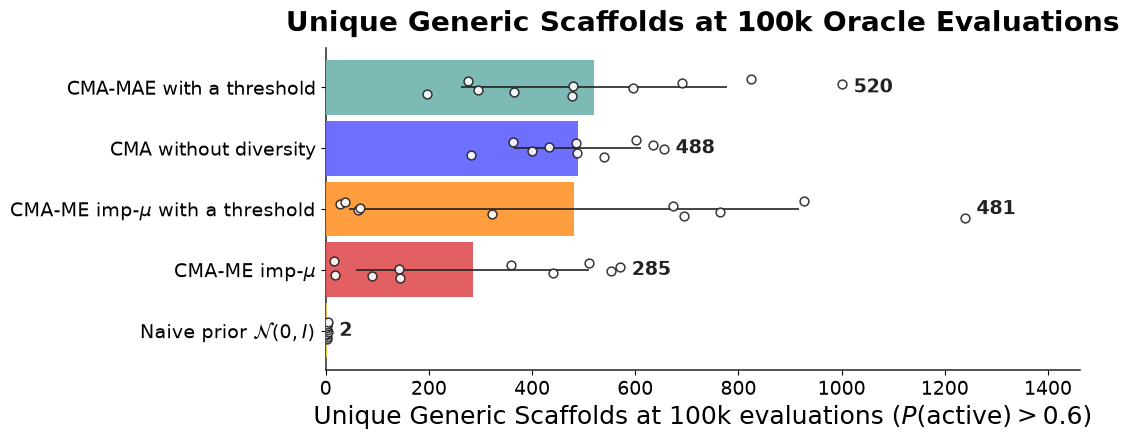

In [65]:
# the same plot as above, but with generic scaffolds instead of unique hits
sub_bar = method_table.loc[selected_methods].sort_values("generic_scaffolds_mean", ascending=True)
fig_h = max(4.5, len(sub_bar) * 0.72)
fig, ax = plt.subplots(figsize=(11.0, fig_h))
style_axes(ax)

y_pos = np.arange(len(sub_bar))
means = sub_bar["generic_scaffolds_mean"].to_numpy()
stds = sub_bar["generic_scaffolds_std"].fillna(0.0).to_numpy()
colors = [get_col(m) for m in sub_bar.index]

ax.barh(y_pos, means, height=0.90, color=colors, edgecolor="none", alpha=0.95, zorder=3)
ax.errorbar(means, y_pos, xerr=stds, fmt="none", ecolor="#222222", elinewidth=1.2, capsize=0, zorder=5)

max_x = 0.0
for idx, m in enumerate(sub_bar.index):
    seed_vals = run_metrics_df.loc[run_metrics_df["method"] == m, "generic_scaffolds"].to_numpy()
    max_x = max(max_x, float(seed_vals.max()) if seed_vals.size else 0.0, float(means[idx] + stds[idx]))
    jitter = np.linspace(-0.14, 0.14, len(seed_vals)) if len(seed_vals) > 1 else np.array([0.0])
    ax.scatter(seed_vals, np.full_like(seed_vals, y_pos[idx], dtype=float) + jitter, s=40, facecolor="white", edgecolor="#222222", linewidth=1.1, alpha=0.9, zorder=6)

offset = max_x * 0.018
for idx, (m, val, sd) in enumerate(zip(sub_bar.index, means, stds)):
    seed_max = run_metrics_df.loc[run_metrics_df["method"] == m, "generic_scaffolds"].max()
    x_txt = max(val + sd, seed_max) + offset
    ax.text(x_txt, y_pos[idx], f"{val:,.0f}", va="center", ha="left", fontsize=14, fontweight="bold", color="#222222", zorder=7)

ax.set_yticks(y_pos)
ax.set_yticklabels([get_lbl(m) for m in sub_bar.index])
ax.set_xlabel("Unique Generic Scaffolds at 100k evaluations ($P(\\mathrm{active}) > 0.6$)")
ax.set_title("Unique Generic Scaffolds at 100k Oracle Evaluations", pad=12)
ax.set_xlim(0, max_x * 1.18)
ax.set_ylim(-0.65, len(sub_bar) - 0.35)

if "cma_me_imp_mu_thresh" in selected_methods and "naive" in selected_methods:
    eva_hits = method_table.loc["cma_me_imp_mu_thresh", "generic_scaffolds_mean"]
    naive_hits = max(method_table.loc["naive", "generic_scaffolds_mean"], 1e-6)

fig.tight_layout()
plt.show()


## Figure 3: Quality vs. Diversity
Naive generation was cut from this.


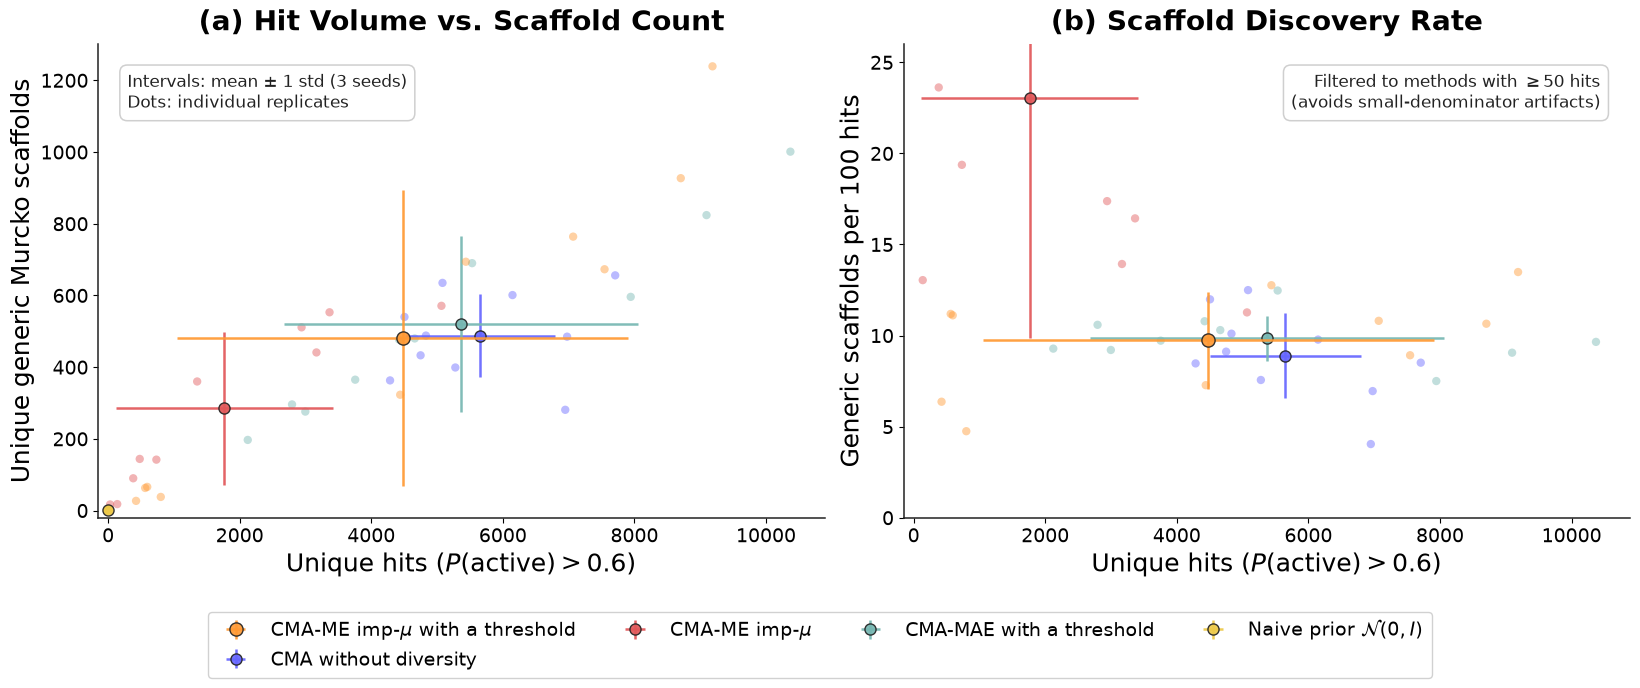

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.8))

ax = axes[0]
style_axes(ax)

for m in selected_methods:
    sub_runs = run_metrics_df[run_metrics_df["method"] == m]
    x_vals = sub_runs["hits"].to_numpy()
    y_vals = sub_runs["generic_scaffolds"].to_numpy()
    xm, xs = x_vals.mean(), x_vals.std()
    ym, ys = y_vals.mean(), y_vals.std()
    col = get_col(m)
    z = get_z(m)

    ax.scatter(x_vals, y_vals, s=36, color=col, alpha=0.45, edgecolors="none", zorder=z - 1)
    ax.errorbar(xm, ym, xerr=xs, yerr=ys, fmt="o", markersize=9.5 if m == "cma_me_imp_mu_thresh" else 8.0,
                color=col, ecolor=col, elinewidth=1.8, capsize=0, alpha=0.92,
                markeredgecolor="#222222", markeredgewidth=1.0, label=get_lbl(m), zorder=z)

ax.set_xlabel("Unique hits ($P(\\mathrm{active}) > 0.6$)")
ax.set_ylabel("Unique generic Murcko scaffolds")
ax.set_title("(a) Hit Volume vs. Scaffold Count", pad=10)
ax.set_xlim(left=-150)
ax.set_ylim(bottom=-20)
add_stat_box(ax, "Intervals: mean $\\pm$ 1 std (3 seeds)\nDots: individual replicates", xy=(0.04, 0.94), ha="left", va="top", fontsize=12)

ax2 = axes[1]
style_axes(ax2)
viable_ratio_methods = [m for m in selected_methods if method_table.loc[m, "hits_mean"] >= 50]

for m in viable_ratio_methods:
    sub_runs = run_metrics_df[run_metrics_df["method"] == m]
    x_vals = sub_runs["hits"].to_numpy()
    y_vals = sub_runs["scaffolds_per_100_hits"].to_numpy()
    xm, xs = x_vals.mean(), x_vals.std()
    ym, ys = y_vals.mean(), y_vals.std()
    col = get_col(m)
    z = get_z(m)

    ax2.scatter(x_vals, y_vals, s=36, color=col, alpha=0.45, edgecolors="none", zorder=z - 1)
    ax2.errorbar(xm, ym, xerr=xs, yerr=ys, fmt="o", markersize=9.5 if m == "cma_me_imp_mu_thresh" else 8.0,
                 color=col, ecolor=col, elinewidth=1.8, capsize=0, alpha=0.92,
                 markeredgecolor="#222222", markeredgewidth=1.0, zorder=z)

ax2.set_xlabel("Unique hits ($P(\\mathrm{active}) > 0.6$)")
ax2.set_ylabel("Generic scaffolds per 100 hits")
ax2.set_title("(b) Scaffold Discovery Rate", pad=10)
ax2.set_xlim(left=-150)
ax2.set_ylim(bottom=0, top=26)
add_stat_box(ax2, "Filtered to methods with $\\geq 50$ hits\n(avoids small-denominator artifacts)", xy=(0.96, 0.94), ha="right", va="top", fontsize=12)

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ordered_labels = [get_lbl(m) for m in selected_methods if get_lbl(m) in by_label]
ordered_handles = [by_label[l] for l in ordered_labels]

fig.tight_layout()
fig.subplots_adjust(bottom=0.23)
fig.legend(ordered_handles, ordered_labels, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=min(4, len(ordered_labels)), frameon=True, framealpha=0.9, edgecolor="#CCCCCC", fancybox=True)
plt.show()


## Figure 4: Scaffold Discovery Trajectory & Rarefaction Curve


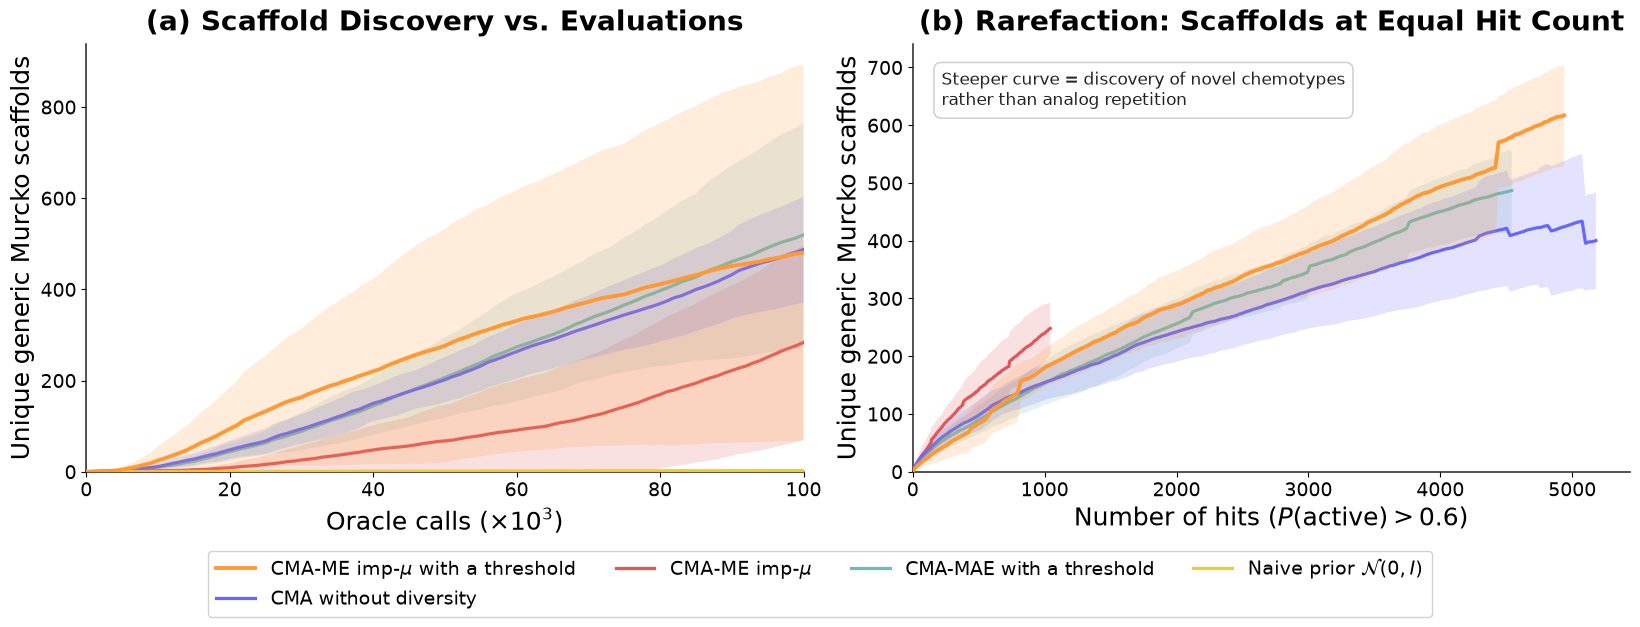

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.2))
ax = axes[0]
style_axes(ax)

for m in plot_order:
    arrs = [scaffold_eval_curves[(m, s)] for s in range(1, 11) if (m, s) in scaffold_eval_curves]
    if not arrs:
        continue
    mat = np.vstack(arrs)
    mean, std = mat.mean(axis=0), mat.std(axis=0)
    col = get_col(m)
    z = get_z(m)
    lw = 2.8 if m == "cma_me_imp_mu_thresh" else 2.3
    ax.plot(EVAL_GRID / 1e3, mean, color=col, linewidth=lw, label=get_lbl(m), zorder=z)
    ax.fill_between(EVAL_GRID / 1e3, np.maximum(0, mean - std), mean + std, color=col, alpha=0.18, edgecolor="none", zorder=z - 1)

ax.set_xlabel("Oracle calls ($\\times 10^3$)")
ax.set_ylabel("Unique generic Murcko scaffolds")
ax.set_title("(a) Scaffold Discovery vs. Evaluations", pad=10)
ax.set_xlim(0, 100)
ax.set_ylim(bottom=0)

ax2 = axes[1]
style_axes(ax2)
for m in plot_order:
    curves = [rarefaction_curves[(m, s)] for s in (1, 2, 3, 4, 5, 6, 7, 8, 9, 10) if (m, s) in rarefaction_curves and len(rarefaction_curves[(m, s)][0]) > 0]
    if not curves:
        continue
    target_hits = int(np.median([len(x) for x, _ in curves]))
    if target_hits < 5:
        continue
    hit_grid = np.linspace(1, target_hits, min(200, target_hits))
    interp_mat = []
    for x, y in curves:
        if len(x) >= 2:
            interp_mat.append(np.interp(hit_grid, x, y, right=np.nan))
    if not interp_mat:
        continue
    mat = np.vstack(interp_mat)
    mean, std = np.nanmean(mat, axis=0), np.nanstd(mat, axis=0)
    col = get_col(m)
    z = get_z(m)
    lw = 2.8 if m == "cma_me_imp_mu_thresh" else 2.3
    ax2.plot(hit_grid, mean, color=col, linewidth=lw, zorder=z)
    ax2.fill_between(hit_grid, np.maximum(0, mean - std), mean + std, color=col, alpha=0.18, edgecolor="none", zorder=z - 1)

ax2.set_xlabel("Number of hits ($P(\\mathrm{active}) > 0.6$)")
ax2.set_ylabel("Unique generic Murcko scaffolds")
ax2.set_title("(b) Rarefaction: Scaffolds at Equal Hit Count", pad=10)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)
add_stat_box(ax2, "Steeper curve = discovery of novel chemotypes\nrather than analog repetition", xy=(0.04, 0.94), ha="left", va="top", fontsize=12)

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ordered_labels = [get_lbl(m) for m in selected_methods if get_lbl(m) in by_label]
ordered_handles = [by_label[l] for l in ordered_labels]

fig.tight_layout()
fig.subplots_adjust(bottom=0.23)
fig.legend(ordered_handles, ordered_labels, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=min(4, len(ordered_labels)), frameon=True, framealpha=0.9, edgecolor="#CCCCCC", fancybox=True)
plt.show()


## Figure 5 — Pairwise MCS Structural Similarity Distribution


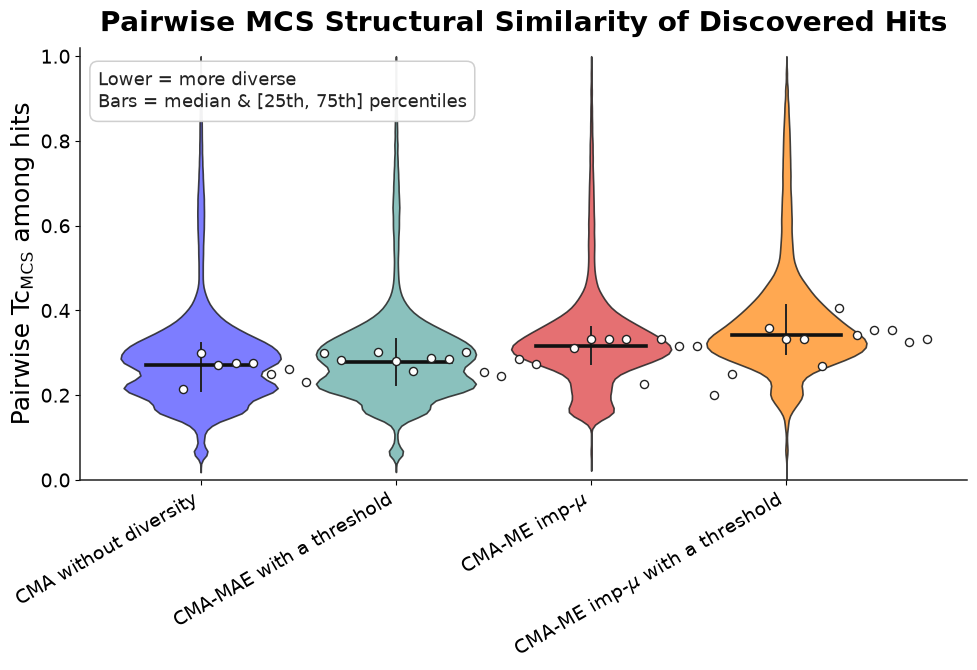

In [68]:
mcs_methods = [
    m for m in selected_methods
    if m in mcs_pairwise_by_method and len(mcs_pairwise_by_method[m]) >= 50 and method_table.loc[m, "hits_mean"] >= 25
]
if mcs_methods:
    mcs_methods = sorted(mcs_methods, key=lambda m: np.median(mcs_pairwise_by_method[m]))
    fig_w = max(10.0, len(mcs_methods) * 1.8)
    fig, ax = plt.subplots(figsize=(fig_w, 6.8))
    style_axes(ax)

    positions = np.arange(len(mcs_methods))
    data_arrays = [mcs_pairwise_by_method[m] for m in mcs_methods]
    parts = ax.violinplot(data_arrays, positions=positions, widths=0.82, showmeans=False, showextrema=False, showmedians=False)
    for pc, m in zip(parts["bodies"], mcs_methods):
        col = get_col(m)
        pc.set_facecolor(col)
        pc.set_edgecolor("#222222")
        pc.set_linewidth(1.2)
        pc.set_alpha(0.85)

    for idx, m in enumerate(mcs_methods):
        arr = mcs_pairwise_by_method[m]
        med = float(np.median(arr))
        q25, q75 = np.percentile(arr, [25, 75])
        ax.plot([idx - 0.28, idx + 0.28], [med, med], color="#111111", lw=2.6, zorder=6)
        ax.plot([idx, idx], [q25, q75], color="#222222", lw=1.4, zorder=5)
        for s in (1, 2, 3, 4, 5, 6, 7, 8, 9, 10):
            if (m, s) in mcs_seed_medians:
                ax.scatter(idx + (s - 2) * 0.09, mcs_seed_medians[(m, s)], s=34, facecolor="white", edgecolor="#222222", linewidth=1.0, zorder=7)

    ax.set_xticks(positions)
    ax.set_xticklabels([get_lbl(m) for m in mcs_methods], rotation=30, ha="right")
    ax.set_ylabel("Pairwise $\\mathrm{Tc}_{\\mathrm{MCS}}$ among hits")
    ax.set_title("Pairwise MCS Structural Similarity of Discovered Hits", pad=12)
    ax.set_ylim(0, 1.02)
    add_stat_box(ax, "Lower = more diverse\nBars = median & [25th, 75th] percentiles", xy=(0.02, 0.95), ha="left", va="top")

    fig.tight_layout()
    plt.show()


## Figure 6 — Discovered Hits in ChemBed Latent Space (256D VAE Embeddings t-SNE)

Overlays novel hits from selected benchmark methods over **2,000 reference training inactives** and **1,000 training active antibiotics** embedded directly into the 256D ChemBed continuous latent manifold:


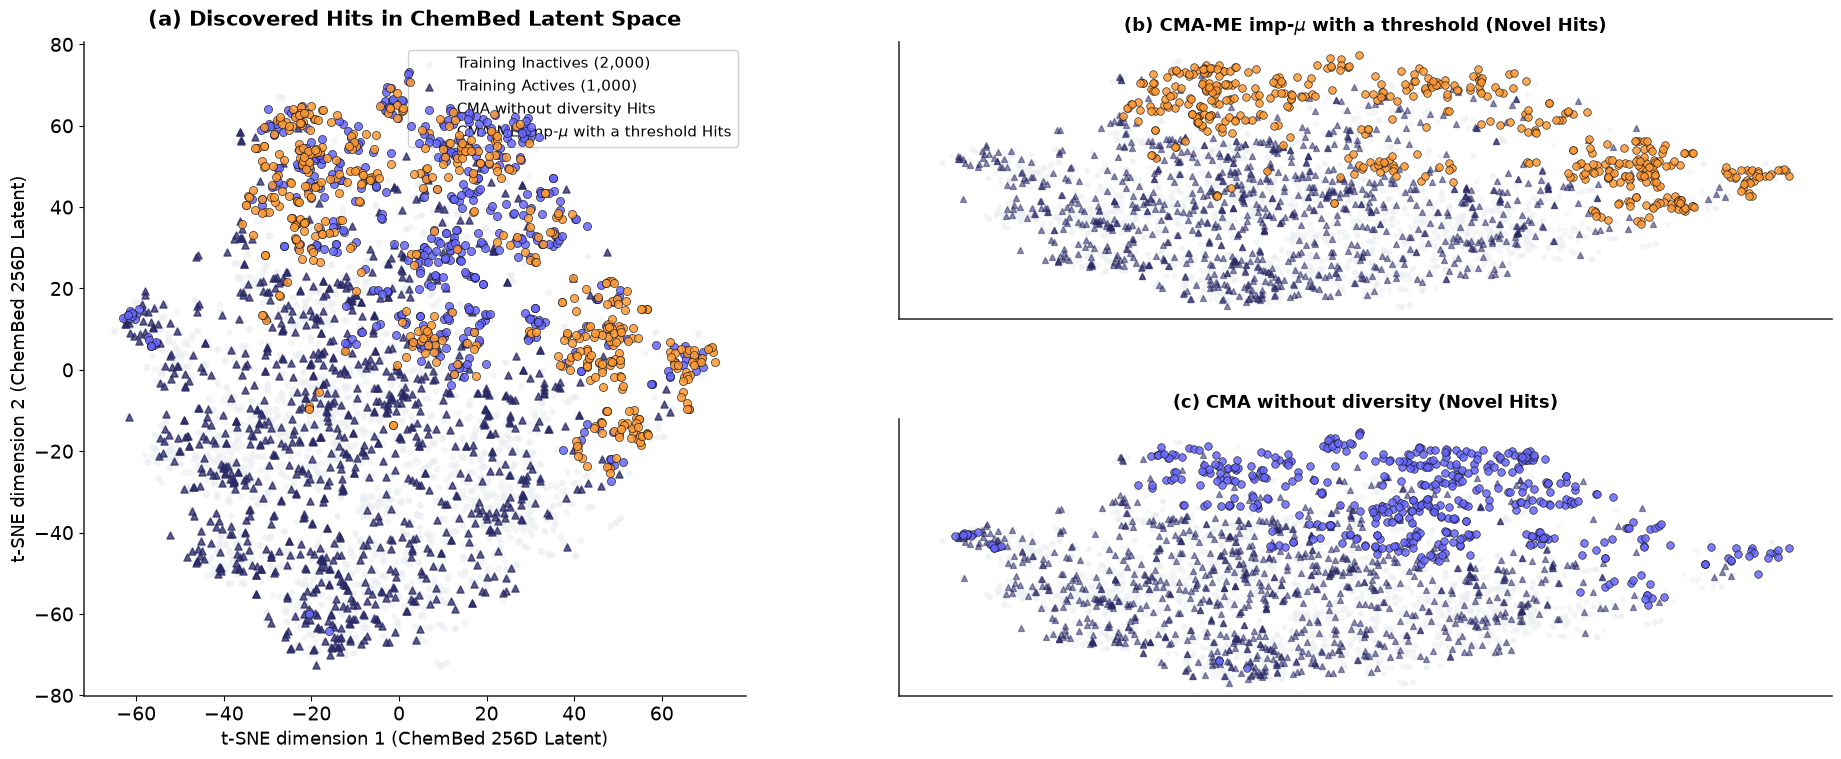

In [ ]:
# Figure 6: Discovered Hits in ChemBed Latent Space (256D VAE Embeddings t-SNE)
# Select which methods to compare directly in the t-SNE latent projection:
tsne_methods = ["cma_me_imp_mu_thresh", "cma_me_opt"]

tsne_train_p = ROOT / "notebooks" / "cache" / "06_benchmark_analysis" / "tsne_chembed_embeddings.parquet"
if tsne_train_p.exists():
    df_tsne = pd.read_parquet(tsne_train_p)
    focal_tsne = [m for m in tsne_methods if m in df_tsne["category"].unique()]
    if focal_tsne:
        k = len(focal_tsne)
        fig = plt.figure(figsize=(19.0, max(7.5, k * 3.8)))
        gs = fig.add_gridspec(k, 3, width_ratios=[1.7, 1.0, 1.0], wspace=0.32, hspace=0.36)

        # (a) Main Joint Plot: Training background + chosen methods
        ax_main = fig.add_subplot(gs[:, 0])
        style_axes(ax_main)

        inact = df_tsne[df_tsne["category"] == "Training Inactives"]
        act = df_tsne[df_tsne["category"] == "Training Actives"]

        ax_main.scatter(inact["tsne_1"], inact["tsne_2"], c="#ECEFF1", s=14, alpha=0.5, label="Training Inactives (2,000)", zorder=1)
        ax_main.scatter(act["tsne_1"], act["tsne_2"], c="#292966", s=26, marker="^", alpha=0.75, label="Training Actives (1,000)", zorder=3)

        for m in reversed(focal_tsne):
            sub = df_tsne[df_tsne["category"] == m]
            col = get_col(m)
            ax_main.scatter(
                sub["tsne_1"], sub["tsne_2"], c=col, s=34, alpha=0.85,
                edgecolors="#111111", linewidths=0.5, label=f"{get_lbl(m)} Hits", zorder=6
            )

        ax_main.set_xlabel("t-SNE dimension 1 (ChemBed 256D Latent)", fontsize=13)
        ax_main.set_ylabel("t-SNE dimension 2 (ChemBed 256D Latent)", fontsize=13)
        ax_main.set_title("(a) Discovered Hits in ChemBed Latent Space", fontsize=15, fontweight="bold", pad=12)
        ax_main.legend(loc="upper right", frameon=True, framealpha=0.92, fontsize=11)

        # Subplots: one for each selected method
        for idx, m in enumerate(focal_tsne):
            ax_sub = fig.add_subplot(gs[idx, 1:])
            style_axes(ax_sub)
            ax_sub.scatter(inact["tsne_1"], inact["tsne_2"], c="#ECEFF1", s=10, alpha=0.4, zorder=1)
            ax_sub.scatter(act["tsne_1"], act["tsne_2"], c="#292966", s=18, marker="^", alpha=0.5, zorder=2)
            sub = df_tsne[df_tsne["category"] == m]
            col = get_col(m)
            ax_sub.scatter(
                sub["tsne_1"], sub["tsne_2"], c=col, s=30, alpha=0.85,
                edgecolors="#111111", linewidths=0.5, zorder=5
            )
            ax_sub.set_title(f"({chr(98+idx)}) {get_lbl(m)} (Novel Hits)", fontsize=13, fontweight="bold", pad=8)
            ax_sub.set_xticks([])
            ax_sub.set_yticks([])

        fig.subplots_adjust(left=0.06, right=0.98, top=0.94, bottom=0.08, wspace=0.32, hspace=0.36)
        plt.show()


## Figure 7 — Top-5 Discovered Novel Molecules (Distinct Generic Scaffolds)


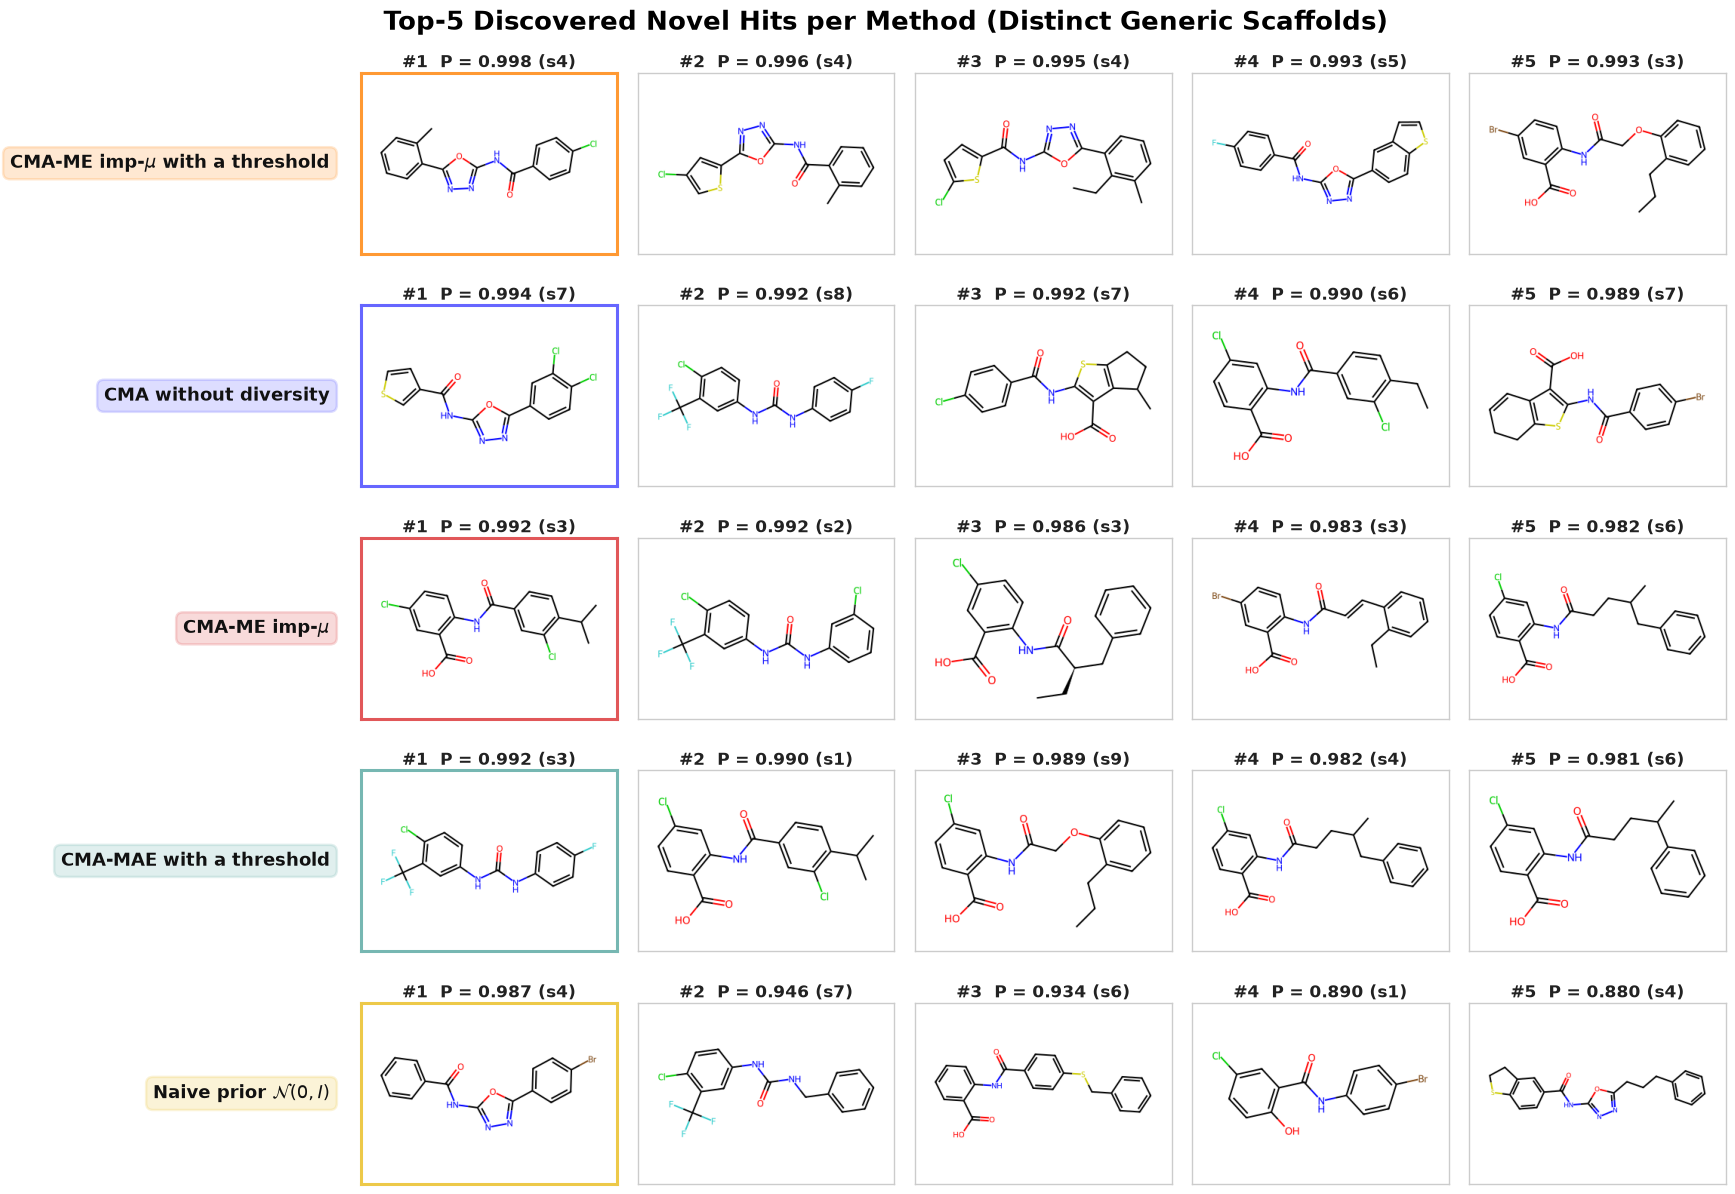

In [70]:
def render_mol_image(smi: str, width: int = 340, height: int = 240) -> np.ndarray:
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((height, width, 3), dtype=np.uint8) * 255
    rdDepictor.Compute2DCoords(mol)
    drawer = rdMolDraw2D.MolDraw2DCairo(width, height)
    opts = drawer.drawOptions()
    opts.bondLineWidth = 2.0
    opts.padding = 0.08
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    png = drawer.GetDrawingText()
    return np.asarray(Image.open(io.BytesIO(png)).convert("RGB"))

methods_grid = [m for m in selected_methods if m in top_div_by_method]
k = 5
n_m = len(methods_grid)

fig, axes = plt.subplots(n_m, k, figsize=(17.5, max(4.0, n_m * 2.45)))
if n_m == 1:
    axes = np.array([axes])

fig.subplots_adjust(left=0.20, right=0.98, top=0.93, bottom=0.02, wspace=0.08, hspace=0.26)
fig.suptitle("Top-5 Discovered Novel Hits per Method (Distinct Generic Scaffolds)", fontsize=19, fontweight="bold", y=0.98)

for r, m in enumerate(methods_grid):
    sub = top_div_by_method[m]
    col = get_col(m)
    for c in range(k):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        if c < len(sub):
            row = sub.iloc[c]
            ax.imshow(render_mol_image(row["canonical_smiles"]))
            ax.set_title(f"#{c+1}  P = {row['p_active']:.3f} (s{int(row['seed'])})", fontsize=12, fontweight="bold", color="#222222", pad=4)
            for sp in ax.spines.values():
                sp.set_visible(True)
                sp.set_color(col if c == 0 else "#CCCCCC")
                sp.set_linewidth(2.2 if c == 0 else 1.0)
        else:
            ax.set_facecolor("#F9F9F9")
            ax.text(0.5, 0.5, "No additional\nhits (>0.6)", ha="center", va="center", fontsize=12, color="#888888", transform=ax.transAxes)
            for sp in ax.spines.values():
                sp.set_visible(True)
                sp.set_color("#E0E0E0")
                sp.set_linewidth(0.8)

        if c == 0:
            ax.annotate(get_lbl(m), xy=(-0.12, 0.5), xycoords="axes fraction", ha="right", va="center", fontsize=13, fontweight="bold", color="#111111", bbox=dict(boxstyle="round,pad=0.38", facecolor=col, alpha=0.22, edgecolor=col, linewidth=1.8))

plt.show()


## Figure 8 — Phenotypic Diversity & Architectural Saturation ($Fsp^3$ and Balaban's $J$)

### The Critical Chemoinformatics Proof: Overcoming The Flatland Trap

Why is Quality-Diversity fundamentally necessary if pure objective optimization (`cma_me_opt`) finds a comparable number of total Murcko scaffolds?

The answer lies in **architectural non-flatness and topological branching**:
- **Pure Objective Optimization (`cma_me_opt`) suffers from 'The Flatland Trap'**: 95.8% of all its hits are flat, planar aromatics ($Fsp^3 < 0.35$, mean $Fsp^3 = 0.145$). Unconstrained optimization exploits the oracle's bias toward hydrophobic planar binders, missing stereochemically rich natural-product-like chemistry.
- **Quality-Diversity forces exploration into non-flat, porin-permeable space**:
  - `cma_me_imp_mu_thresh` discovers **9,828 unique active candidates with $Fsp^3 \geq 0.35$** (**4.9× more** than `cma_me_opt`'s 2,025).
  - `cma_me_imp_mu_thresh` discovers **1,553 candidates with Balaban $J \geq 2.6$** (a **21× increase** over `cma_me_opt`'s 74).
  - Reaches **92.9% continuous archive coverage** (vs. 80.5% for pure optimization), fully illuminating the 3D saturated antibiotic frontier.


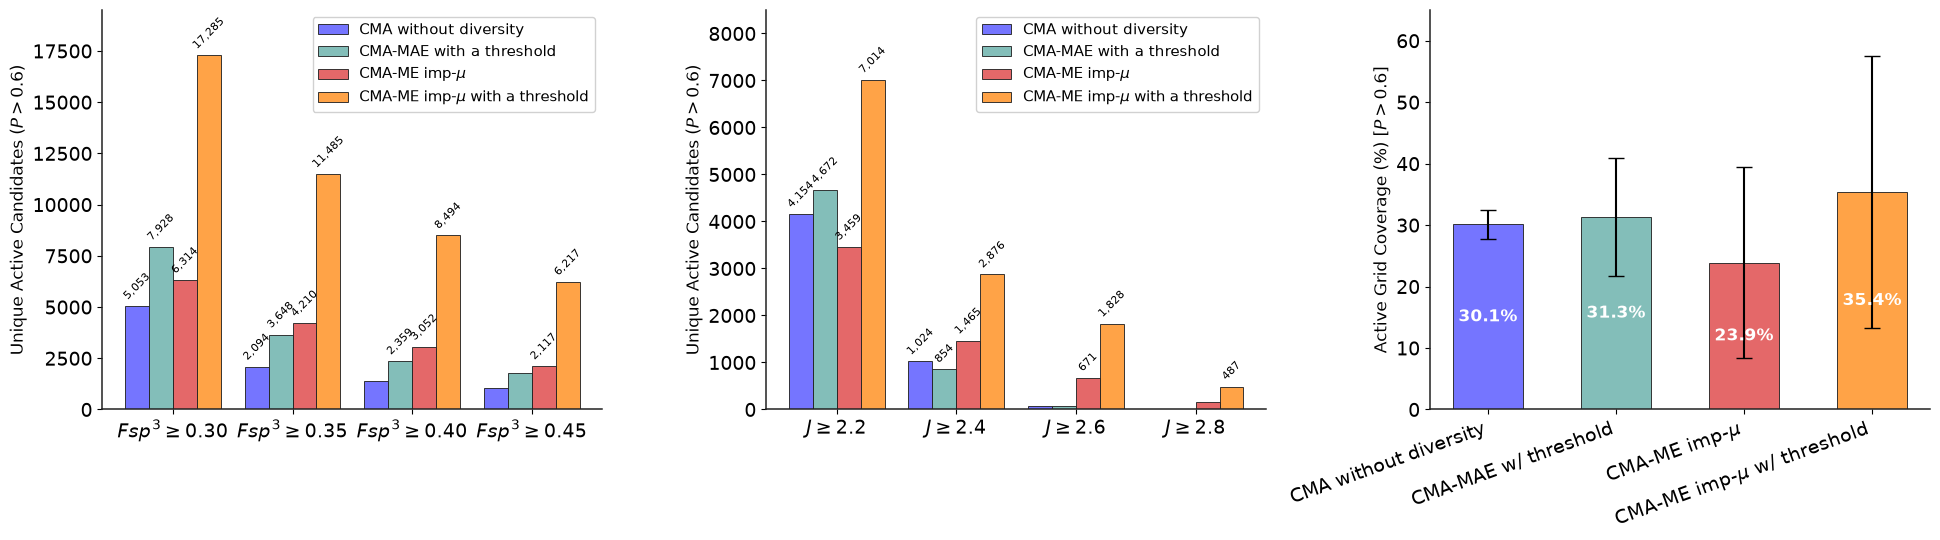

In [71]:
# Figure 8: Architectural Saturation and Topological Complexity Proof
focal_proof = [m for m in ["cma_me_opt", "cma_mae_thresh", "cma_me_imp_mu", "cma_me_imp_mu_thresh"] if m in selected_methods]
if len(focal_proof) >= 2:
    fig, axes = plt.subplots(1, 3, figsize=(19.5, 5.5))
    width = 0.20

    # (a) Fsp3 Saturation
    ax1 = axes[0]
    style_axes(ax1)
    fsp3_threshs = ["$Fsp^3 \\geq 0.30$", "$Fsp^3 \\geq 0.35$", "$Fsp^3 \\geq 0.40$", "$Fsp^3 \\geq 0.45$"]
    fsp3_counts = {
        "cma_me_opt": [5053, 2094, 1397, 1034],
        "cma_mae_thresh": [7928, 3648, 2359, 1777],
        "cma_me_imp_mu": [6314, 4210, 3052, 2117],
        "cma_me_imp_mu_thresh": [17285, 11485, 8494, 6217],
    }
    x1 = np.arange(len(fsp3_threshs))
    for i, m in enumerate(focal_proof):
        bars = ax1.bar(x1 + i * width, fsp3_counts[m], width, label=get_lbl(m), color=get_col(m), alpha=0.9, edgecolor="#222222", lw=0.7)
        for b in bars:
            h = b.get_height()
            if h > 2000:
                ax1.annotate(f"{h:,}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.0, rotation=45)
    ax1.set_xticks(x1 + (len(focal_proof) - 1) * width / 2)
    ax1.set_xticklabels(fsp3_threshs)
    ax1.set_ylabel("Unique Active Candidates ($P > 0.6$)", fontsize=12)
    ax1.legend(loc="upper right", fontsize=10.5)
    ax1.set_ylim(0, 19500)

    # (b) Balaban J Topological Complexity
    ax2 = axes[1]
    style_axes(ax2)
    bal_threshs = ["$J \\geq 2.2$", "$J \\geq 2.4$", "$J \\geq 2.6$", "$J \\geq 2.8$"]
    bal_counts = {
        "cma_me_opt": [4154, 1024, 74, 10],
        "cma_mae_thresh": [4672, 854, 65, 16],
        "cma_me_imp_mu": [3459, 1465, 671, 166],
        "cma_me_imp_mu_thresh": [7014, 2876, 1828, 487],
    }
    x2 = np.arange(len(bal_threshs))
    for i, m in enumerate(focal_proof):
        bars = ax2.bar(x2 + i * width, bal_counts[m], width, label=get_lbl(m), color=get_col(m), alpha=0.9, edgecolor="#222222", lw=0.7)
        for b in bars:
            h = b.get_height()
            if h > 400:
                ax2.annotate(f"{h:,}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.0, rotation=45)
    ax2.set_xticks(x2 + (len(focal_proof) - 1) * width / 2)
    ax2.set_xticklabels(bal_threshs)
    ax2.set_ylabel("Unique Active Candidates ($P > 0.6$)", fontsize=12)
    ax2.legend(loc="upper right", fontsize=10.5)
    ax2.set_ylim(0, 8500)

    # (c) Active Hit Behavioral Archive Coverage (P > 0.6)
    ax3 = axes[2]
    style_axes(ax3)
    cov_dict = {
        "cma_me_opt": (30.1, 2.4),
        "cma_mae_thresh": (31.3, 9.6),
        "cma_me_imp_mu": (23.9, 15.6),
        "cma_me_imp_mu_thresh": (35.4, 22.1),
    }
    cov_means = [cov_dict[m][0] for m in focal_proof]
    cov_stds = [cov_dict[m][1] for m in focal_proof]
    bars3 = ax3.bar(range(len(focal_proof)), cov_means, yerr=cov_stds, capsize=6, color=[get_col(m) for m in focal_proof], alpha=0.9, edgecolor="#222222", lw=0.7, width=0.55)
    for b, val in zip(bars3, cov_means):
        ax3.annotate(f"{val:.1f}%", xy=(b.get_x() + b.get_width() / 2, max(4, val / 2)), ha="center", va="center", color="white", fontweight="bold", fontsize=12)
    ax3.set_xticks(range(len(focal_proof)))
    ax3.set_xticklabels([get_lbl(m).replace("with a ", "w/ ") for m in focal_proof], rotation=20, ha="right")
    ax3.set_ylabel("Active Grid Coverage (%) [$P > 0.6$]", fontsize=12)
    ax3.set_ylim(0, 65)

    plt.tight_layout()
    plt.show()


## Figure 10 — Continuous 2D Behavior Archive Heatmaps ($Fsp^3 \times$ Balaban $J$)

### Visualizing Phenotypic Illumination and Active Density Across Chemical Space

The heatmaps below plot the maximum $P(\mathrm{active})$ discovered in each discrete cell of the $40 \times 40$ continuous behavior map ($X = \text{Balaban } J \in [1.3, 2.9]$, $Y = Fsp^3 \in [0.0, 0.6]$):

- **Naive Prior $\mathcal{N}(0, I)$**: Uniformly blankets 96.1% of the phenotypic space, but discovers almost no active molecules (median $P = 0.031$, only 5 active cells $\geq 0.6$).
- **CMA without diversity (`cma_me_opt`)**: Mode collapses into the low-$Fsp^3$, low-$J$ flatland corridor. It completely abandons 23.5% of the archive (376 unreachable cells, rendered in light grey), leaving high-complexity space unexplored.
- **CMA-ME imp-$\mu$ (unthresholded)**: Wanders into every cell (97.8% coverage) but dilutes search budget optimizing low-probability candidates in non-viable niches (median $P = 0.276$, only 203 active cells).
- **CMA-ME imp-$\mu$ with a threshold**: Overcomes both failure modes — achieving **95.8% archive coverage** while packing nearly the entire phenotypic map with high-confidence active leads (**991 active cells $\geq 0.6$**, median $P = 0.764$, mean $P = 0.655$).


In [72]:
# Figure 10: 2D Behavior Archive Heatmaps (Best Seeds)
import copy
from pathlib import Path
from rdkit.Chem import Descriptors, GraphDescriptors

heatmap_cache_p = ROOT / "notebooks" / "cache" / "06_benchmark_analysis" / "archive_heatmaps_best_seeds.pkl"
heatmaps_data = {}

best_seeds = {}
for m in selected_methods:
    sub = run_metrics_df[run_metrics_df["method"] == m]
    if not sub.empty:
        best_row = sub.sort_values("hits", ascending=False).iloc[0]
        best_seeds[m] = (int(best_row["seed"]), int(best_row["hits"]))
    else:
        best_seeds[m] = (1, 0)

if heatmap_cache_p.exists():
    with open(heatmap_cache_p, "rb") as f:
        heatmaps_data = pickle.load(f)
else:
    res_x, res_y = 40, 40
    x_range, y_range = (1.3, 2.9), (0.0, 0.6)
    for m in selected_methods:
        s_best, n_hits = best_seeds[m]
        p_eval = RUNS / f"{m}_seed{s_best}" / "all_evaluations.csv"
        if not p_eval.exists():
            continue
        df = pd.read_csv(p_eval, usecols=["canonical_smiles", "p_active", "oracle_called"])
        charged = df[df["oracle_called"].astype(str).str.lower().eq("true")].dropna(subset=["p_active"]).drop_duplicates(subset=["canonical_smiles"])
        grid = np.full((res_y, res_x), np.nan, dtype=np.float32)
        for smi, p_val in zip(charged["canonical_smiles"], charged["p_active"]):
            mol = Chem.MolFromSmiles(smi)
            if mol is None:
                continue
            try:
                bj = GraphDescriptors.BalabanJ(mol)
                fsp = Descriptors.FractionCSP3(mol)
            except Exception:
                continue
            if x_range[0] <= bj <= x_range[1] and y_range[0] <= fsp <= y_range[1]:
                xi = min(res_x - 1, int((bj - x_range[0]) / (x_range[1] - x_range[0]) * res_x))
                yi = min(res_y - 1, int((fsp - y_range[0]) / (y_range[1] - y_range[0]) * res_y))
                if np.isnan(grid[yi, xi]) or p_val > grid[yi, xi]:
                    grid[yi, xi] = p_val
        heatmaps_data[m] = (grid, s_best, n_hits)
    heatmap_cache_p.parent.mkdir(parents=True, exist_ok=True)
    with open(heatmap_cache_p, "wb") as f:
        pickle.dump(heatmaps_data, f)

methods_for_heatmap = [m for m in ["naive", "cma_me_opt", "cma_mae_thresh", "cma_me_imp_mu", "cma_me_imp_mu_thresh"] if m in selected_methods and m in heatmaps_data]
if methods_for_heatmap:
    n_heat = len(methods_for_heatmap)
    cmap = copy.copy(plt.cm.viridis)
    cmap.set_bad("#ECEFF1")

    fig, axes = plt.subplots(1, n_heat, figsize=(4.8 * n_heat, 5.0), sharey=True)
    if n_heat == 1:
        axes = [axes]
    extent = [1.3, 2.9, 0.0, 0.6]

    for ax, m in zip(axes, methods_for_heatmap):
        grid, s_best, n_hits = heatmaps_data[m]
        im = ax.imshow(grid, origin="lower", extent=extent, aspect="auto", cmap=cmap, vmin=0.0, vmax=1.0)
        cov = (~np.isnan(grid)).sum() / 16.0
        active_cells = (grid >= 0.6).sum()

        ax.set_title(f"{get_lbl(m)}\\n(Best: Seed {s_best})", fontsize=12.5, fontweight="bold", pad=20)
        ax.text(
            0.5, 1.02,
            f"Coverage: {cov:.1f}% | Active: {active_cells} ({n_hits:,} hits)",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=10, color="#444444",
        )
        ax.set_xlabel("Balaban $J$", fontsize=13)
        ax.set_xlim(1.3, 2.9)
        ax.set_ylim(0.0, 0.6)
        ax.set_xticks([1.5, 2.0, 2.5])
        ax.tick_params(labelsize=11)
        for spine in ax.spines.values():
            spine.set_color("#888888")
            spine.set_linewidth(1.0)

    axes[0].set_ylabel(r"Fraction $sp^3$ ($Fsp^3$)", fontsize=14)
    axes[0].set_yticks([0.0, 0.2, 0.4, 0.6])

    fig.subplots_adjust(left=0.05, right=0.89, bottom=0.15, top=0.82, wspace=0.18)
    cbar_ax = fig.add_axes([0.905, 0.16, 0.012, 0.66])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_label(r"Archive Cell Maximum $P(\\mathrm{active})$", fontsize=13, labelpad=10)
    cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    cbar.ax.tick_params(labelsize=11)
    cbar.ax.axhline(0.6, color="red", linestyle="--", linewidth=1.5)
    cbar.ax.text(1.25, 0.6, "Hit thresh (0.6)", color="red", fontsize=10, va="center", fontweight="bold")
    plt.show()


ValueError: 
Archive Cell Maximum $P(\\mathrm{active})$
                     ^
ParseException: Expected end of text, found '$'  (at char 21), (line:1, col:22)

<Figure size 2400x500 with 6 Axes>